# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [5]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [6]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[ns]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   object        
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[ns](1), int32(1), int64(7), object(1)
memory usage: 650.2+ KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [7]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

Saved bg_hourly_2019.csv — a row per hour of 2019.


## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

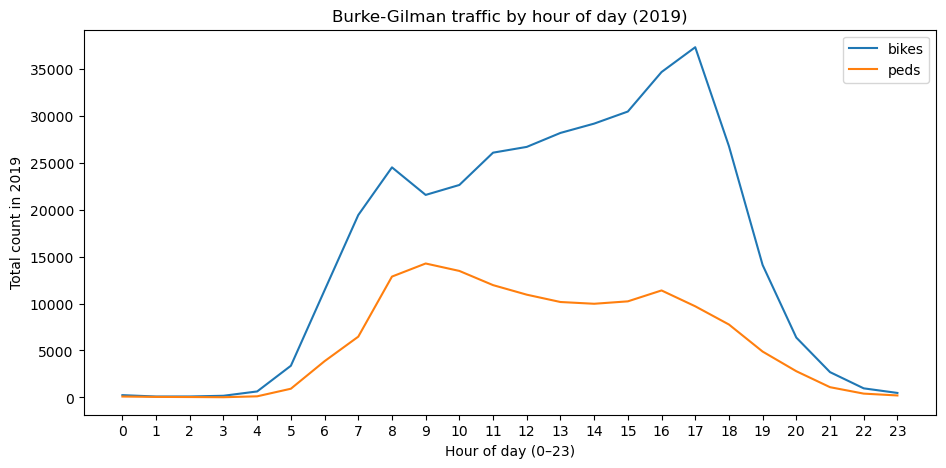

In [8]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

Busiest hour:  17:00  (129 people per hour on average)
Quietest hour: 2:00  (0.4 people per hour on average)

Average people per hour, by part of day:
hour
Afternoon/evening (15-18)    115.2
Midday (10-14)               103.7
Morning (6-9)                 78.3
Late evening (19-23)          18.6
Night (0-5)                    2.7


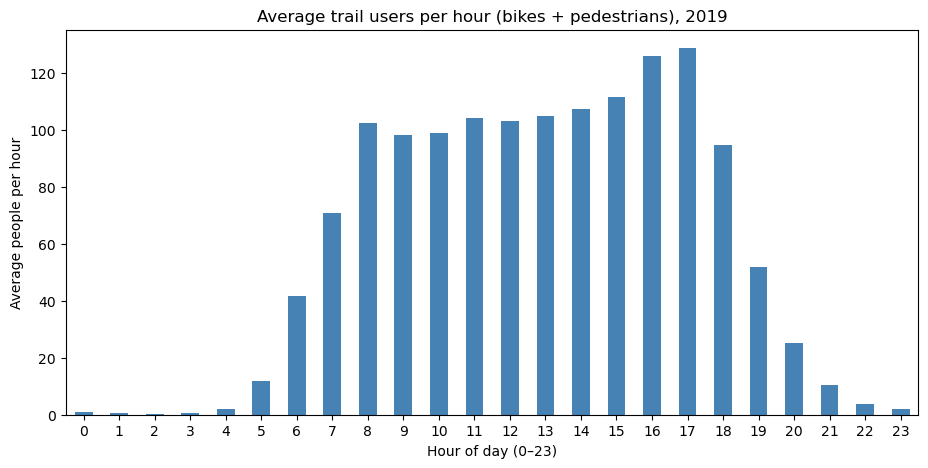

In [9]:
# Your code for Q1 (or put a Google Sheets link in your written answer below)
df["total"] = df["bikes"] + df["peds"]

avg_by_hour = df.groupby("hour")["total"].mean()
print(f"Busiest hour:  {avg_by_hour.idxmax()}:00  ({avg_by_hour.max():.0f} people per hour on average)")
print(f"Quietest hour: {avg_by_hour.idxmin()}:00  ({avg_by_hour.min():.1f} people per hour on average)")

# A single hour can be noisy, so also compare longer stretches of the day
part_of_day = pd.cut(df["hour"], bins=[-1, 5, 9, 14, 18, 23],
                     labels=["Night (0-5)", "Morning (6-9)", "Midday (10-14)",
                             "Afternoon/evening (15-18)", "Late evening (19-23)"])
avg_by_part = df.groupby(part_of_day, observed=True)["total"].mean().round(1)
print("\nAverage people per hour, by part of day:")
print(avg_by_part.sort_values(ascending=False).to_string())

avg_by_hour.plot(kind="bar", figsize=(11, 5), color="steelblue")
plt.title("Average trail users per hour (bikes + pedestrians), 2019")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Average people per hour")
plt.xticks(rotation=0)
plt.show()

**Your Q1 answer:**

*I defined busy as the average number of trail users per hour, combining both bikes and pedestrians because I wanted to understand the overall trail activity. Based on the data, the busiest hour is 5:00 PM, with an average of 129 people per hour, while the quietest hour is 2:00 AM, with only 0.4 people per hour. Looking at longer periods, the afternoon and evening (3–6 PM) are the busiest, averaging 115.2 people per hour, while nighttime (12–5 AM) is the quietest, averaging 2.7 people per hour. I chose to compare both individual hours and longer periods because it helps identify the peak hour while also showing overall patterns throughout the day.*

**Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

Peak hour for bikes:       17:00
Peak hour for pedestrians: 9:00

% of each group's daily traffic in each window:
                      bikes  peds
Morning rush (7-9)     17.8  23.4
Midday (10-15)         44.3  46.4
Evening rush (16-18)   26.8  20.1


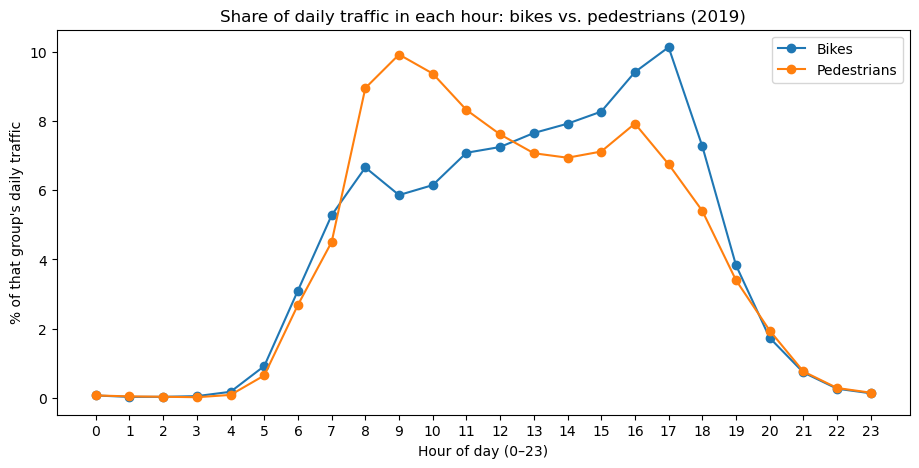

In [10]:
# Your code for Q2
avg_by_mode = df.groupby("hour")[["bikes", "peds"]].mean()
pct_of_day = avg_by_mode / avg_by_mode.sum() * 100

print(f"Peak hour for bikes:       {pct_of_day['bikes'].idxmax()}:00")
print(f"Peak hour for pedestrians: {pct_of_day['peds'].idxmax()}:00")

# How much of each group's traffic falls in commute hours vs. the middle of the day
windows = {"Morning rush (7-9)": [7, 8, 9],
           "Midday (10-15)": [10, 11, 12, 13, 14, 15],
           "Evening rush (16-18)": [16, 17, 18]}
summary = pd.DataFrame({name: pct_of_day.loc[hours].sum() for name, hours in windows.items()}).T.round(1)
print("\n% of each group's daily traffic in each window:")
print(summary.to_string())

pct_of_day.plot(figsize=(11, 5), marker="o")
plt.title("Share of daily traffic in each hour: bikes vs. pedestrians (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("% of that group's daily traffic")
plt.xticks(range(0, 24))
plt.legend(["Bikes", "Pedestrians"])
plt.show()

**Your Q2 answer:**

*Based on the data, cyclists and pedestrians use the trail at different times of the day. Cyclists are most active at 5:00 PM, while pedestrians peak earlier at 9:00 AM. During the morning rush (7–9 AM), pedestrians account for 23.4% of their daily traffic compared to 17.8% for cyclists. However, during the evening rush (4–6 PM), cyclists have a higher share at 26.8% compared to 20.1% for pedestrians. Both groups are active throughout midday, but cyclists show a higher increase in the afternoon. The explanation that I can interpret from the data is that more cyclists use the trail for commuting home from work, while pedestrians may use it more for morning walks or exercise.  *

**Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

Average daily count by day of week:
            bikes   peds
weekday                 
Monday      965.0  358.0
Tuesday     907.0  340.0
Wednesday   900.0  335.0
Thursday    882.0  333.0
Friday      848.0  328.0
Saturday   1284.0  500.0
Sunday     1274.0  562.0

Bikes: weekday is 1.5x weekend at rush hour (7-8am, 5pm), and 0.3x weekend at midday (12-2pm)

Pedestrians: weekday is 0.7x weekend at rush hour (7-8am, 5pm), and 0.5x weekend at midday (12-2pm)


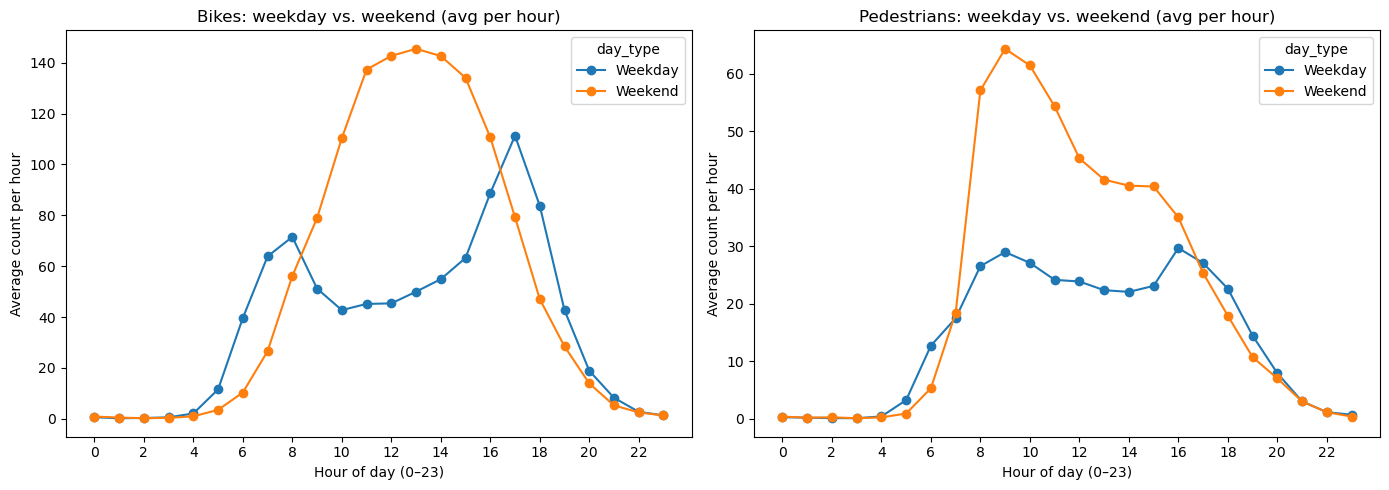

In [11]:
# Your code for Q3
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["day_type"] = df["weekday"].map(lambda d: "Weekend" if d in ["Saturday", "Sunday"] else "Weekday")

# 1) Average DAILY traffic on each day of the week
daily = df.groupby([df["date"].dt.date, "weekday"])[["bikes", "peds"]].sum().reset_index()
avg_daily_by_weekday = daily.groupby("weekday")[["bikes", "peds"]].mean().reindex(order).round(0)
print("Average daily count by day of week:")
print(avg_daily_by_weekday.to_string())

# 2) Hourly pattern, weekdays vs. weekends (average per hour)
bikes_hourly = df.groupby(["hour", "day_type"])["bikes"].mean().unstack()
peds_hourly = df.groupby(["hour", "day_type"])["peds"].mean().unstack()

# 3) A simple commuting test: weekday ÷ weekend traffic at rush hour vs. midday
rush, midday = [7, 8, 17], [12, 13, 14]
for label, table in [("Bikes", bikes_hourly), ("Pedestrians", peds_hourly)]:
    rush_ratio = table.loc[rush, "Weekday"].mean() / table.loc[rush, "Weekend"].mean()
    midday_ratio = table.loc[midday, "Weekday"].mean() / table.loc[midday, "Weekend"].mean()
    print(f"\n{label}: weekday is {rush_ratio:.1f}x weekend at rush hour (7-8am, 5pm), "
          f"and {midday_ratio:.1f}x weekend at midday (12-2pm)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
bikes_hourly.plot(ax=axes[0], marker="o", title="Bikes: weekday vs. weekend (avg per hour)")
peds_hourly.plot(ax=axes[1], marker="o", title="Pedestrians: weekday vs. weekend (avg per hour)")
for ax in axes:
    ax.set_xlabel("Hour of day (0–23)")
    ax.set_ylabel("Average count per hour")
    ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()


**Your Q3 answer:**

*I would say that the commuting pattern as having higher trail activity during weekday rush hours, especially in the morning (7–9 AM) and evening (4–6 PM), compared to weekends. Based on the data, there is evidence that people use the Burke-Gilman Trail for commuting. During rush hours, weekday bike traffic is 1.5 times higher than on weekends, with peak around 5:00 PM. However, on weekends, both cyclists and pedestrians are more active during midday, which meant that recreational activities like biking, walking, or exercising. Pedestrians show a weaker commuting pattern since their weekday rush-hour traffic is only 0.7 times that of weekends. In conclusion, I think the data show signs that the trial is used for both recreational purposes and commuting. *

**Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

Weekdays only:
             % northbound, morning (6-9am)  % northbound, evening (3-6pm)
Bikes                                 71.1                           32.2
Pedestrians                           54.3                           48.1


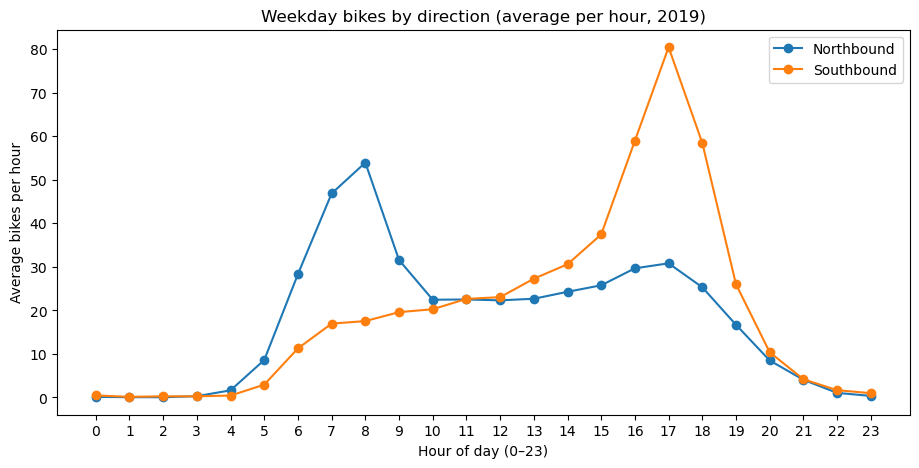

In [12]:
# Your code for Q4
weekdays = df[df["day_type"] == "Weekday"]
direction = weekdays.groupby("hour")[["bike_north", "bike_south", "ped_north", "ped_south"]].mean()

def pct_northbound(hours, mode):
    rows = direction.loc[hours]
    north, south = rows[f"{mode}_north"].sum(), rows[f"{mode}_south"].sum()
    return round(north / (north + south) * 100, 1)

morning, evening = [6, 7, 8, 9], [15, 16, 17, 18]
flow = pd.DataFrame({
    "% northbound, morning (6-9am)": [pct_northbound(morning, "bike"), pct_northbound(morning, "ped")],
    "% northbound, evening (3-6pm)": [pct_northbound(evening, "bike"), pct_northbound(evening, "ped")],
}, index=["Bikes", "Pedestrians"])
print("Weekdays only:")
print(flow.to_string())

direction[["bike_north", "bike_south"]].plot(figsize=(11, 5), marker="o")
plt.title("Weekday bikes by direction (average per hour, 2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Average bikes per hour")
plt.xticks(range(0, 24))
plt.legend(["Northbound", "Southbound"])
plt.show()

**Your Q4 answer:**

*(write here)*

## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

*(write here)*

## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.